# GLASS Dedicated Pair Plots

Build publication-count/SI plots and category-driver plots only for GLASS pathogen-antibiotic pairs with available SI data.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines import (
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_si_and_clean_glass_list,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    save_category_driver_plots,
    save_interesting_si_plots,
    summarize_pathogen_coverage,
)

## Parameters

In [3]:
OUTPUT_DIR = PROJECT_ROOT / "outputs"
PARQUET_OUTPUT_DIR = OUTPUT_DIR / "parquets"
FIGURE_OUTPUT_DIR = OUTPUT_DIR / "figures"
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ASSETS_DIR = PROJECT_ROOT / "assets"
YEARLY_SCREENED_PATH = PARQUET_OUTPUT_DIR / "yearly_amr_screened_pairs.parquet"
UNIFIED_DECISIONS_PATH = PARQUET_OUTPUT_DIR / "yearly_amr_unified_decisions.parquet"
PATHOGEN_BG_PATH = PARQUET_OUTPUT_DIR / "pathogen_tiab_counts.parquet"
ANTIBIOTIC_BG_PATH = PARQUET_OUTPUT_DIR / "antibiotic_tiab_counts.parquet"
ANTIBIOTIC_COARSENING_PATH = ASSETS_DIR / "antibiotic_coarsening_lookup.csv"
DRIVER_CATEGORY_COARSENING_PATH = ASSETS_DIR / "amr_driver_category_coarsening.csv"

GLASS_XLSX_PATH = ASSETS_DIR / "GLASS list.xlsx"
GLASS_CLEANED_PATH = ASSETS_DIR / "glass_amr_cleaned.csv"
BACTERIA_SYNONYM_PATH = ASSETS_DIR / "bacteria_synonym_lookup.csv"
ANTIBIOTIC_SYNONYM_PATH = ASSETS_DIR / "antibiotic_synonym_lookup.csv"

ANTIBIOTIC_ANALYSIS_LEVEL = "antibiotic"  # antibiotic, Class, Simplified categories, High level categories, Origin
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
GLASS_SI_PLOT_DIR = FIGURE_OUTPUT_DIR / "glass_yearly_si_plots"
GLASS_DRIVER_PLOT_DIR = FIGURE_OUTPUT_DIR / "glass_yearly_si_driver_plots"

FIT_START_YEAR = 2000
FIT_END_YEAR = 2023
CURVE_FIT_END_YEAR = 2025
NUM_FUTURE_YEARS = 5
PLOT_END_YEAR = CURVE_FIT_END_YEAR + NUM_FUTURE_YEARS
MIN_AVG_AMR_PUBLICATIONS_PER_YEAR = 5.0

LOESS_FRAC = 0.6
LOESS_DEGREE = 1
TAIL_DAMPING_YEARS = None
FILL_MISSING_AMR_COUNTS_WITH_ZERO = True

CATEGORY_INCLUDE_DECISIONS = ("yes", "uncertain")
DRIVER_CATEGORY_LEVEL = "coarse"  # use "original" for fine LLM categories
DRIVER_LOOKBACK_YEARS = 5
FIGURE_FORMAT = "pdf"
DISPLAY_PLOTS = True
MAX_DISPLAY_PLOTS = 10
MAX_GLASS_PLOTS = None  # set to an int for a quick subset

## Load Inputs

In [4]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)

yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_unfiltered_df = yearly_screened_model_df.copy()
yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    min_avg_amr_publications_per_year=MIN_AVG_AMR_PUBLICATIONS_PER_YEAR,
)

pathogen_filter_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_unfiltered_df,
    modeled_df=yearly_screened_model_df,
    source_label="model input before publication filter",
    modeled_label="model input after publication filter",
)
display(pathogen_filter_summary_df.query("status != 'present_in_both'"))

if YEARLY_SI_PATH.exists():
    si_df = pd.read_parquet(YEARLY_SI_PATH)
    print(f"Loaded SI rows: {len(si_df):,} from {YEARLY_SI_PATH}")
else:
    si_df, pooled_model, design_columns = build_yearly_si_dataset(
        yearly_screened_model_df,
        pathogen_bg_df,
        antibiotic_bg_model_df,
        output_path=YEARLY_SI_PATH,
    )
    print(f"Built SI rows: {len(si_df):,} and saved to {YEARLY_SI_PATH}")

si_pathogen_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_df,
    modeled_df=si_df,
    source_label="filtered model input",
    modeled_label="yearly SI output",
)
display(si_pathogen_summary_df.query("status != 'present_in_both'"))

_, glass_pairs_df = load_si_and_clean_glass_list(
    YEARLY_SI_PATH,
    GLASS_XLSX_PATH,
    bacteria_synonym_path=BACTERIA_SYNONYM_PATH,
    antibiotic_synonym_path=ANTIBIOTIC_SYNONYM_PATH,
    antibiotic_coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    glass_cleaned_path=GLASS_CLEANED_PATH,
)

display(glass_pairs_df.head())


yearly_screened rows: 22,872
yearly_screened unique pathogens: 48
yearly_screened unique antibiotics: 197
yearly_screened year range: 2000 - 2026
pathogen bg rows: 1,296
antibiotic bg rows: 5,319
unified decision rows available for driver analysis: 161,140
Antibiotic analysis level: individual antibiotic.
model yearly rows: 22,872
model pathogen-antibiotic rows: 2,903
model antibiotic values: 197
model antibiotic background rows: 5,319
model unified decision rows: 161,140
AMR publication filter: kept 208 / 2,903 pairs with >= 5 publications/year on average from 2000 to 2023.
model input before publication filter pathogens: 48
model input after publication filter pathogens: 17
Pathogens present in model input before publication filter but absent from model input after publication filter: 31
Aggregatibacter actinomycetemcomitans, Bacillus anthracis, Bordetella pertussis, Borrelia burgdorferi, Brucella melitensis, Burkholderia cepacia, Burkholderia pseudomallei, Chlamydia pneumoniae, Chla

,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Aggregatibacter actinomycetemcomitans,97,114,21,0.0,0.0,0.0,True,False,missing_from_modeled
1,Bacillus anthracis,78,62,47,0.0,0.0,0.0,True,False,missing_from_modeled
2,Bordetella pertussis,71,97,25,0.0,0.0,0.0,True,False,missing_from_modeled
3,Borrelia burgdorferi,41,43,23,0.0,0.0,0.0,True,False,missing_from_modeled
4,Brucella melitensis,124,170,31,0.0,0.0,0.0,True,False,missing_from_modeled
5,Burkholderia cepacia,262,403,48,0.0,0.0,0.0,True,False,missing_from_modeled
6,Burkholderia pseudomallei,163,227,47,0.0,0.0,0.0,True,False,missing_from_modeled
7,Chlamydia pneumoniae,45,47,21,0.0,0.0,0.0,True,False,missing_from_modeled
8,Chlamydia trachomatis,150,154,38,0.0,0.0,0.0,True,False,missing_from_modeled
9,Clostridium perfringens,265,412,67,0.0,0.0,0.0,True,False,missing_from_modeled


Loaded SI rows: 6,209 from /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/yearly_si.parquet
filtered model input pathogens: 17
yearly SI output pathogens: 19
Pathogens present in yearly SI output but absent from filtered model input: 2
Listeria monocytogenes, Streptococcus pyogenes


,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Listeria monocytogenes,0.0,0.0,0.0,23,128,1,False,True,only_in_modeled
1,Streptococcus pyogenes,0.0,0.0,0.0,26,144,1,False,True,only_in_modeled


Loaded SI rows: 6,209 from /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/yearly_si.parquet
Pathogens: 19; antibiotics/levels: 60
Saved cleaned GLASS rows: 89 to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/assets/glass_amr_cleaned.csv


,raw_pathogen,raw_antibiotic,pathogen,antibiotic,pathogen_standardized,antibiotic_standardized,Class,Simplified categories,High level categories,Origin
0,Acinetobacter spp.,amikacin,Acinetobacter baumannii,Amikacin,True,True,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
1,Acinetobacter spp.,Colistin,Acinetobacter baumannii,Colistin,True,False,Polymyxins,Miscellaneous,Other,Naturally occurring/modified
2,Acinetobacter spp.,doripenem,Acinetobacter baumannii,Doripenem,True,True,Carbapenems,Penems/Carbapenems,Beta lactam and related,Naturally occurring/modified
3,Acinetobacter spp.,Gentamicin,Acinetobacter baumannii,Gentamicin,True,False,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
4,Acinetobacter spp.,Imipenem,Acinetobacter baumannii,Imipenem/cilastatin,True,True,Carbapenems,Penems/Carbapenems,Beta lactam and related,Naturally occurring/modified


## Keep GLASS Pairs With SI Data

In [5]:
si_pairs_df = si_df[["pathogen", "antibiotic"]].drop_duplicates()
glass_candidate_pairs_df = glass_pairs_df[["pathogen", "antibiotic"]].drop_duplicates()

glass_available_pairs_df = (
    glass_candidate_pairs_df.merge(si_pairs_df, on=["pathogen", "antibiotic"], how="inner")
    .sort_values(["pathogen", "antibiotic"])
    .reset_index(drop=True)
)

latest_counts_df = (
    si_df.sort_values("year")
    .groupby(["pathogen", "antibiotic"], as_index=False)
    .tail(1)[["pathogen", "antibiotic", "year", "count", "SI"]]
    .rename(columns={"year": "latest_year", "count": "latest_count", "SI": "latest_SI"})
)

glass_plot_pairs_df = (
    glass_available_pairs_df.merge(latest_counts_df, on=["pathogen", "antibiotic"], how="left")
    .sort_values(["latest_count", "pathogen", "antibiotic"], ascending=[False, True, True])
    .reset_index(drop=True)
)
if MAX_GLASS_PLOTS is not None:
    glass_plot_pairs_df = glass_plot_pairs_df.head(int(MAX_GLASS_PLOTS)).copy()

print(f"GLASS candidate pairs: {len(glass_candidate_pairs_df):,}")
print(f"GLASS pairs with SI data: {len(glass_available_pairs_df):,}")
print(f"GLASS pairs selected for plotting: {len(glass_plot_pairs_df):,}")
display(glass_plot_pairs_df.head(30))

GLASS candidate pairs: 89
GLASS pairs with SI data: 52
GLASS pairs selected for plotting: 52


,pathogen,antibiotic,latest_year,latest_count,latest_SI
0,Escherichia coli,Ciprofloxacin,2026,79,0.667422
1,Escherichia coli,Colistin,2026,63,0.598504
2,Escherichia coli,Sulfamethoxazole/trimethoprim,2026,53,0.647139
3,Escherichia coli,Ceftazidime,2026,46,0.415420
4,Escherichia coli,Meropenem,2026,46,0.453344
5,Klebsiella pneumoniae,Ceftazidime,2026,46,0.396761
6,Klebsiella pneumoniae,Colistin,2026,45,0.436424
7,Klebsiella pneumoniae,Meropenem,2026,44,0.415800
8,Acinetobacter baumannii,Colistin,2026,43,0.546761
9,Klebsiella pneumoniae,Ciprofloxacin,2026,38,0.336738


## Build Category Driver Inputs

In [6]:
category_counts_df, glass_with_drivers_df = build_si_driver_analysis(
    interesting_df=glass_plot_pairs_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=CURVE_FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=None,
)

driver_pairs_df = glass_plot_pairs_df.merge(
    category_counts_df[["pathogen", "antibiotic"]].drop_duplicates(),
    on=["pathogen", "antibiotic"],
    how="inner",
)

print(f"Category-count rows: {len(category_counts_df):,}")
print(f"GLASS pairs with category-driver data: {len(driver_pairs_df):,}")
display(glass_with_drivers_df.head(30))

Saved SI driver explanations to None
Category-count rows: 15,166
GLASS pairs with category-driver data: 50


,pathogen,antibiotic,latest_year,latest_count,latest_SI,driver_recent_total,driver_previous_total,driver_count_change,driver_dominant_category,driver_dominant_category_count,driver_fastest_growing_category,driver_fastest_growing_category_change,driver_weak_signal_share,driver_manual_review_share,driver_central_count,driver_partial_count,driver_incidental_count
0,Escherichia coli,Ciprofloxacin,2026,79,0.667422,988,587,401,RESISTANCE_PREVALENCE_SURVEILLANCE,649,ONE_HEALTH_ENVIRONMENTAL_RESERVOIR,0.021596,0.000000,0.910931,987,1,0
1,Escherichia coli,Colistin,2026,63,0.598504,746,379,367,RESISTANCE_PREVALENCE_SURVEILLANCE,346,ONE_HEALTH_ENVIRONMENTAL_RESERVOIR,0.015442,0.002681,0.941019,738,6,2
2,Escherichia coli,Sulfamethoxazole/trimethoprim,2026,53,0.647139,524,376,148,RESISTANCE_PREVALENCE_SURVEILLANCE,443,RESISTANCE_PREVALENCE_SURVEILLANCE,0.020952,0.000000,0.803435,524,0,0
3,Escherichia coli,Ceftazidime,2026,46,0.415420,395,183,212,RESISTANCE_PREVALENCE_SURVEILLANCE,285,RESISTANCE_PREVALENCE_SURVEILLANCE,0.054852,0.002532,0.898734,394,0,1
4,Escherichia coli,Meropenem,2026,46,0.453344,506,185,321,RESISTANCE_PREVALENCE_SURVEILLANCE,319,TREATMENT_EFFECTIVENESS,0.039237,0.000000,0.901186,506,0,0
5,Klebsiella pneumoniae,Ceftazidime,2026,46,0.396761,359,120,239,RESISTANCE_PREVALENCE_SURVEILLANCE,166,RESISTANCE_MECHANISM,0.173236,0.002786,0.908078,358,0,1
6,Klebsiella pneumoniae,Colistin,2026,45,0.436424,489,202,287,RESISTANCE_PREVALENCE_SURVEILLANCE,211,RESISTANCE_PREVALENCE_SURVEILLANCE,0.030503,0.004090,0.887526,481,6,2
7,Klebsiella pneumoniae,Meropenem,2026,44,0.415800,401,161,240,RESISTANCE_PREVALENCE_SURVEILLANCE,195,RESISTANCE_MECHANISM,0.125385,0.000000,0.852868,400,1,0
8,Acinetobacter baumannii,Colistin,2026,43,0.546761,326,179,147,RESISTANCE_PREVALENCE_SURVEILLANCE,137,RESISTANCE_PREVALENCE_SURVEILLANCE,0.096223,0.000000,0.901840,324,2,0
9,Klebsiella pneumoniae,Ciprofloxacin,2026,38,0.336738,333,153,180,RESISTANCE_PREVALENCE_SURVEILLANCE,215,DIAGNOSTIC_STEWARDSHIP,0.028440,0.000000,0.864865,333,0,0


## Save Dedicated Plots

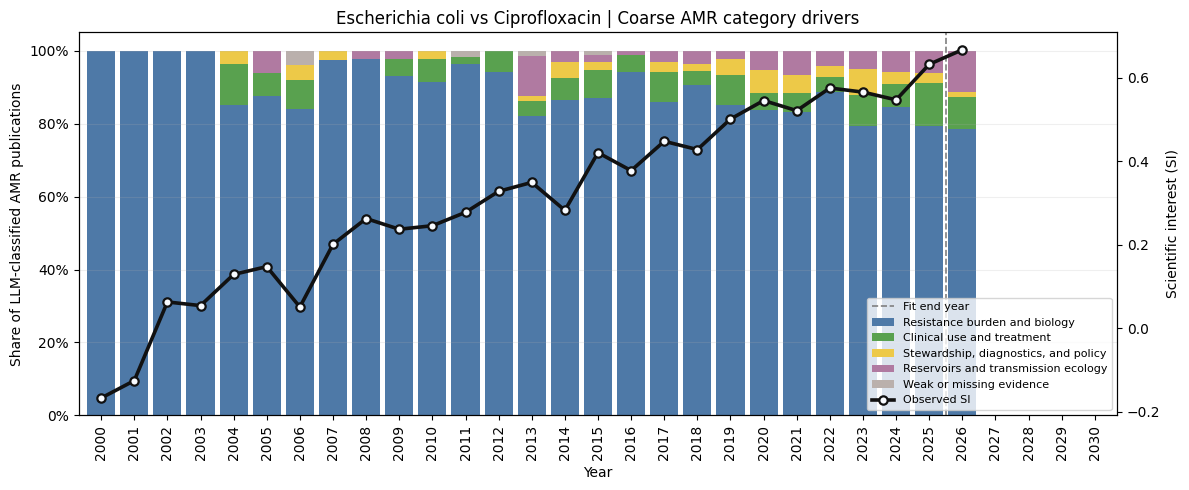

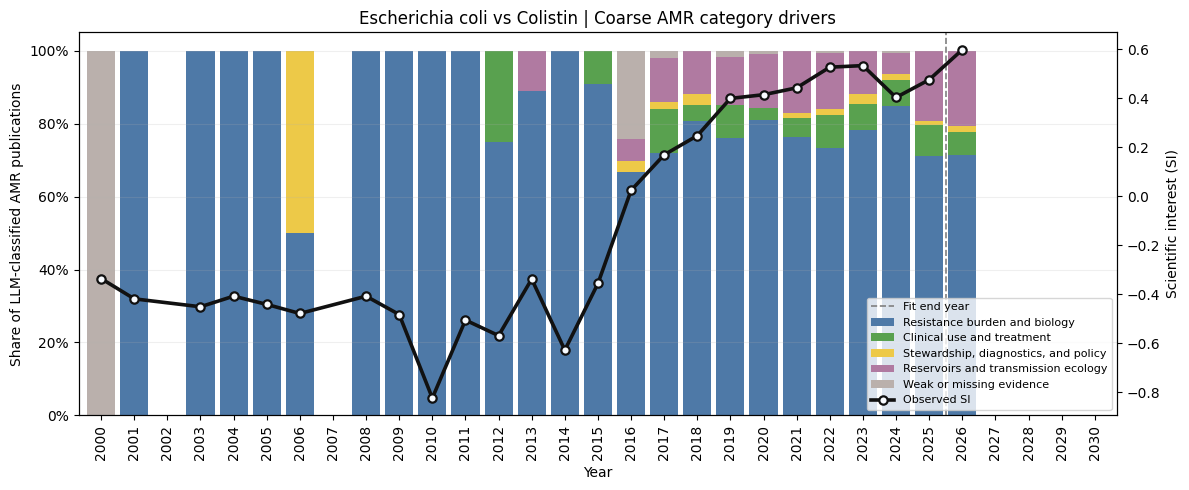

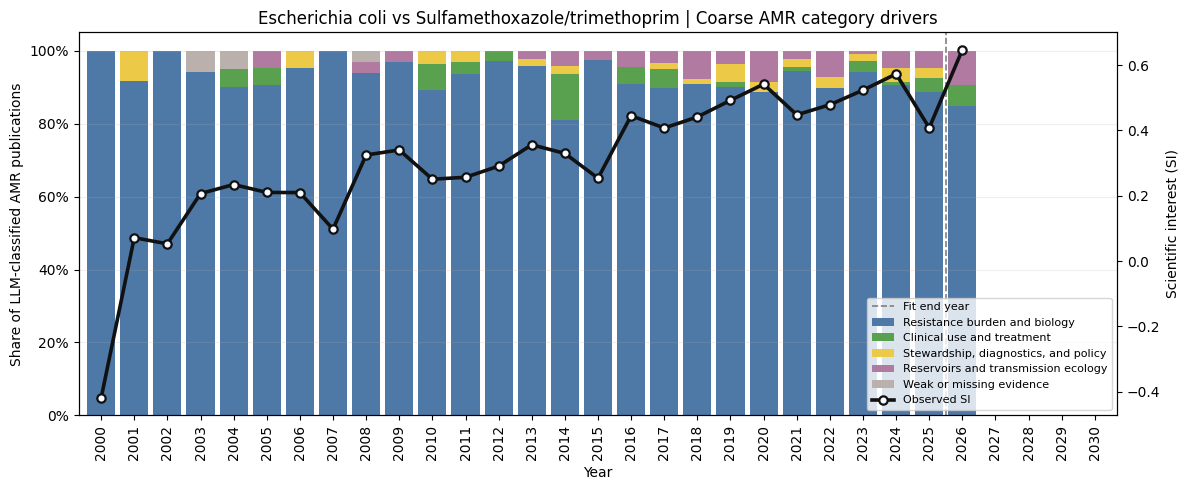

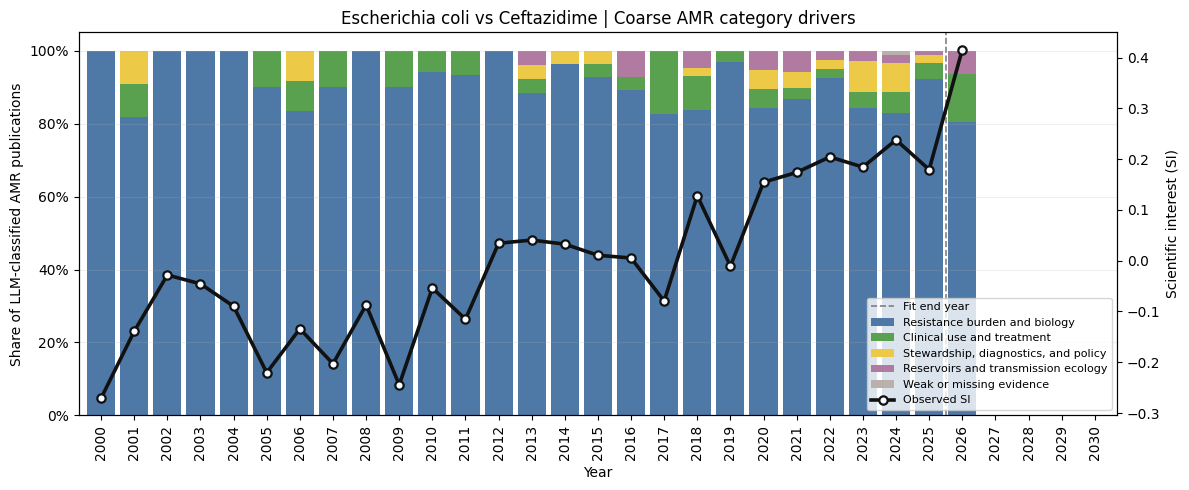

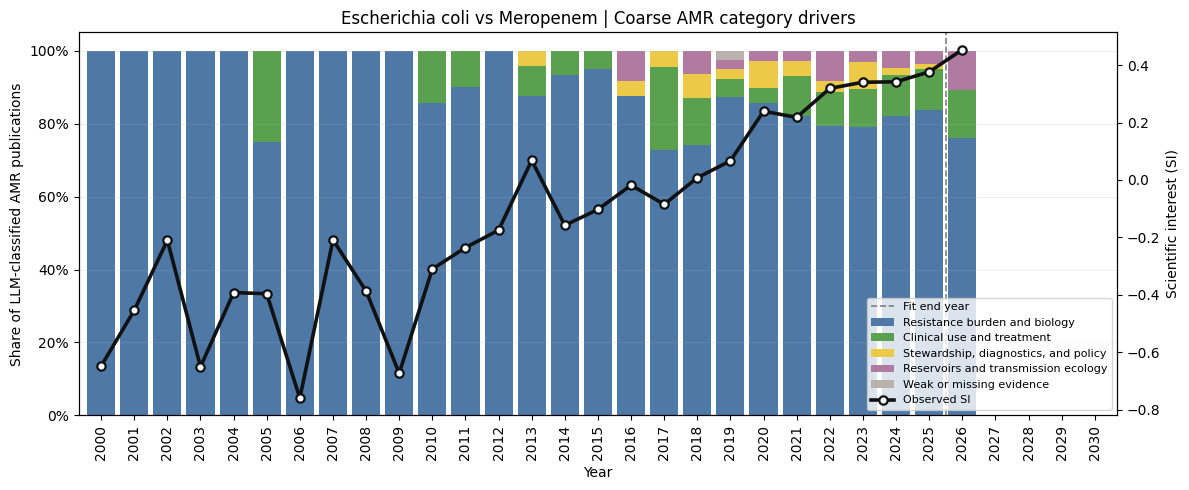

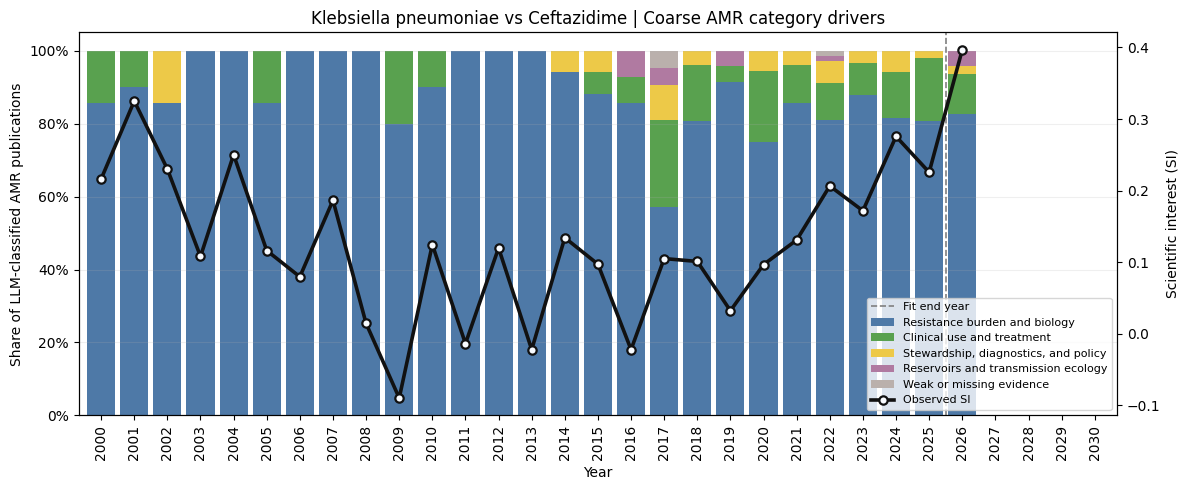

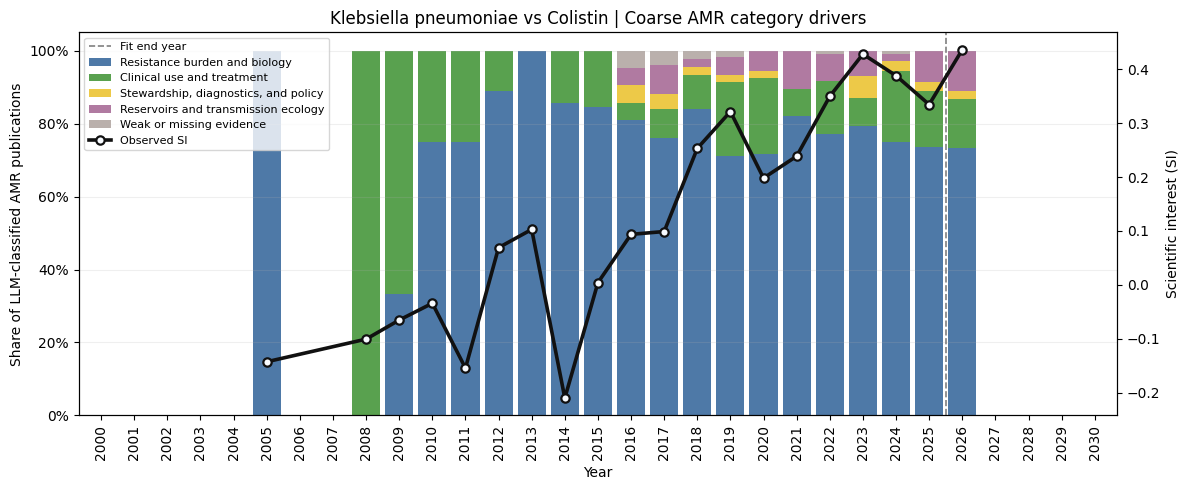

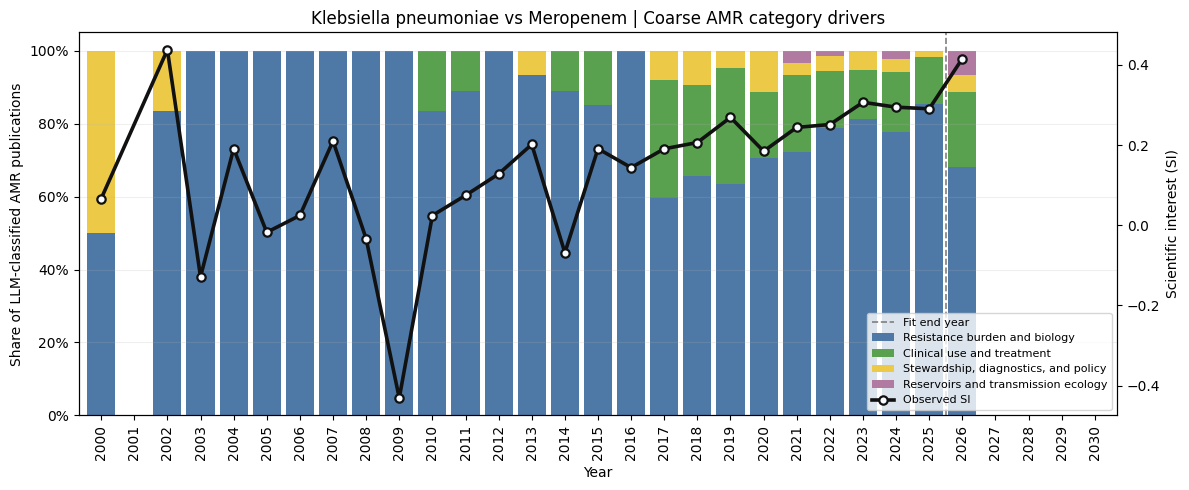

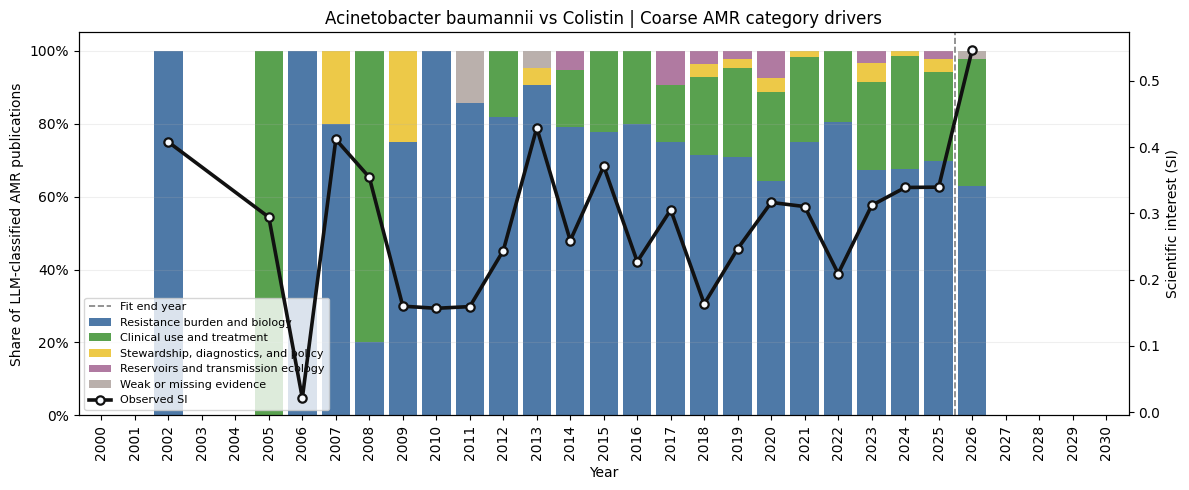

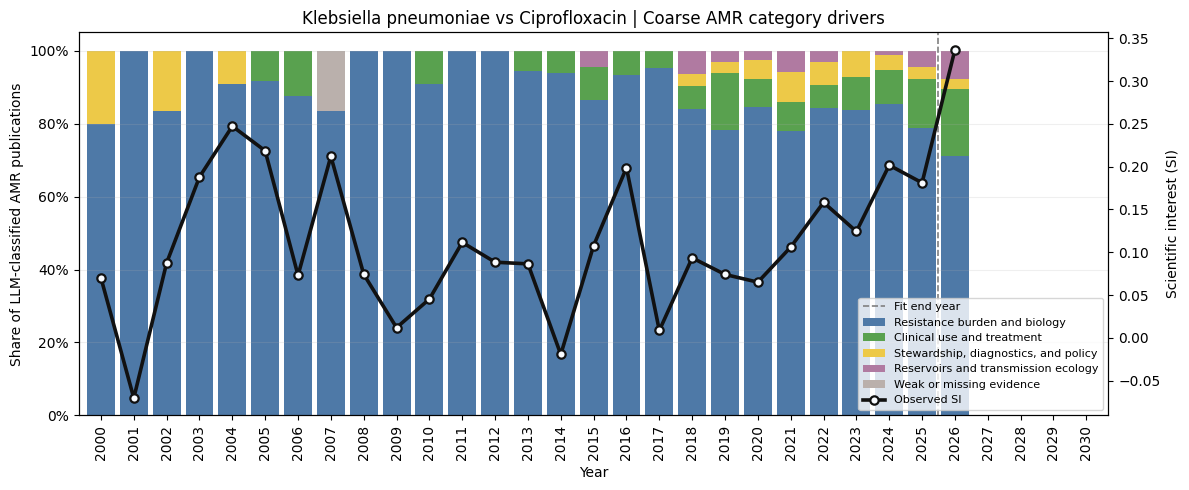

Saved 50 coarse category driver plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/glass_yearly_si_driver_plots
Displayed 10 category driver plots inline.
Saved GLASS driver plots: 50 -> /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/glass_yearly_si_driver_plots


In [7]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=driver_pairs_df,
    output_dir=GLASS_DRIVER_PLOT_DIR,
    start_year=FIT_START_YEAR,
    end_year=PLOT_END_YEAR,
    fit_end_year=CURVE_FIT_END_YEAR,
    max_plots=len(driver_pairs_df),
    figure_format=FIGURE_FORMAT,
    driver_category_level=DRIVER_CATEGORY_LEVEL,
    category_coarsening_path=DRIVER_CATEGORY_COARSENING_PATH,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)

print(f"Saved GLASS driver plots: {saved_driver_plots:,} -> {GLASS_DRIVER_PLOT_DIR}")

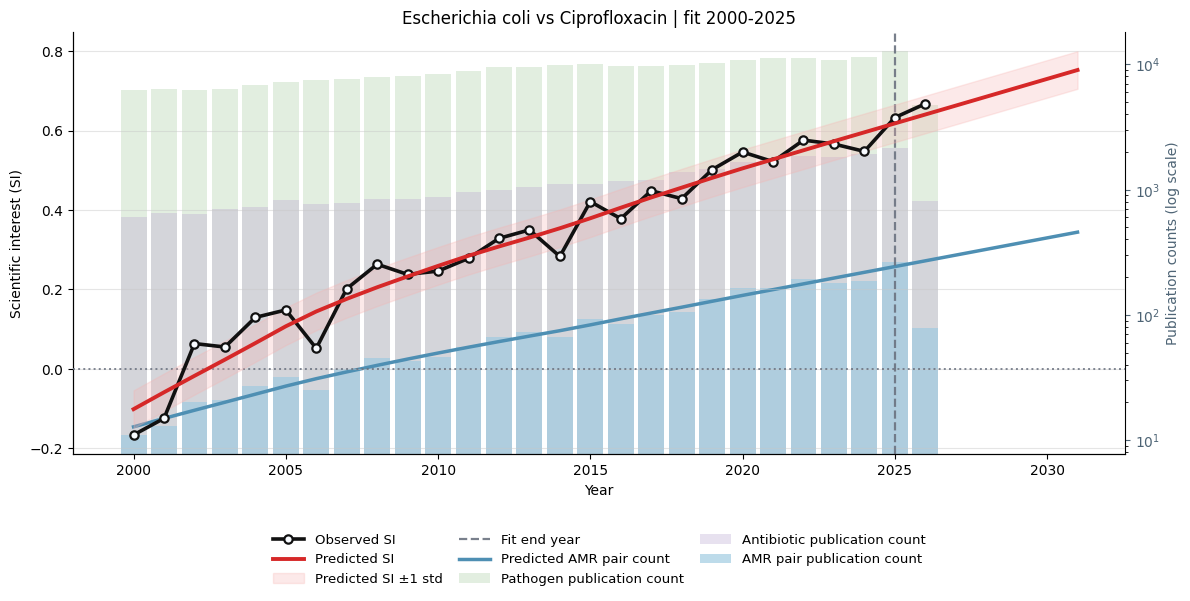

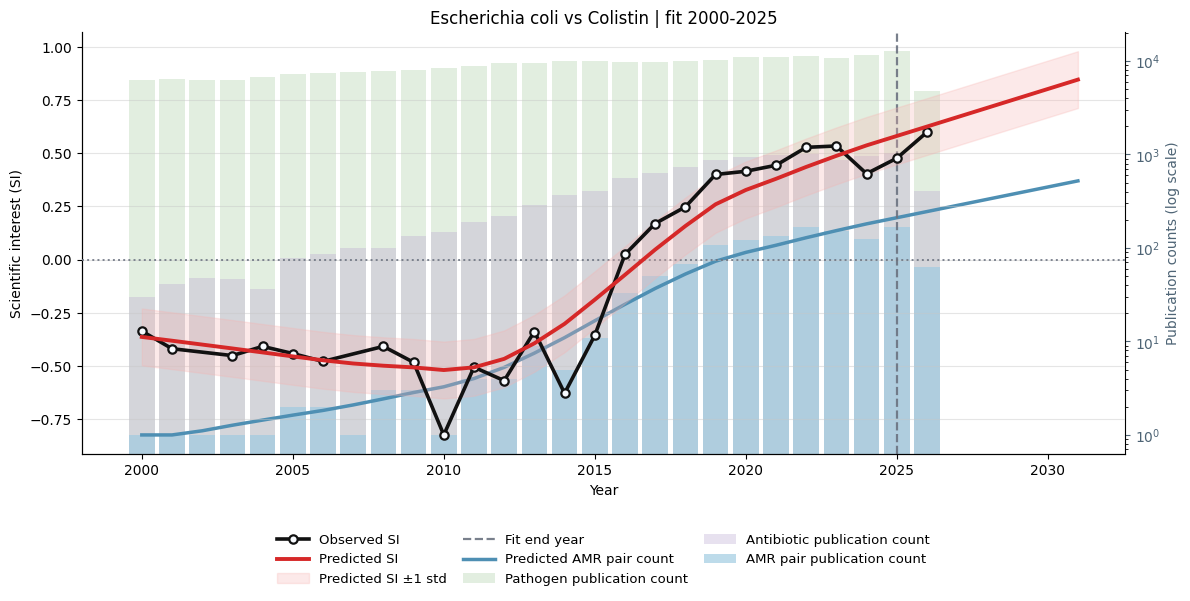

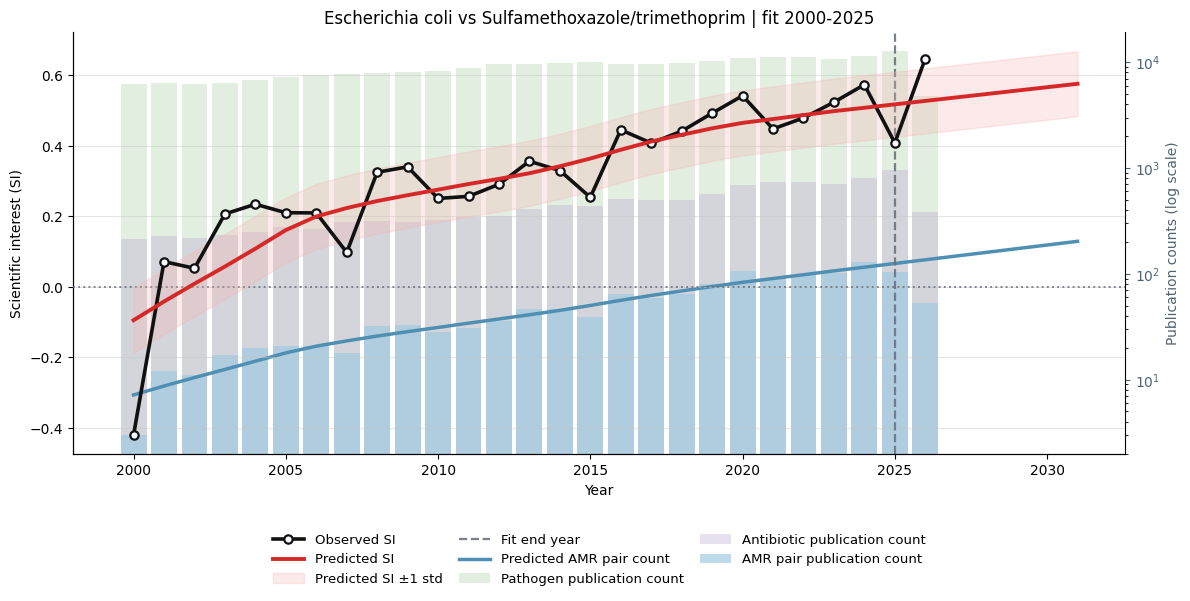

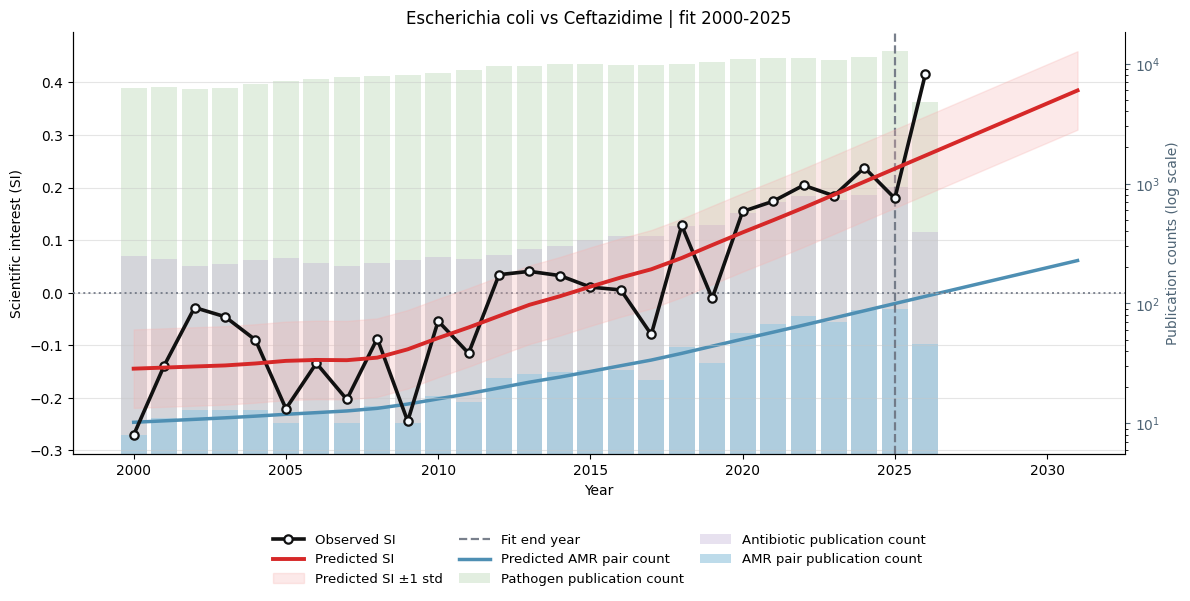

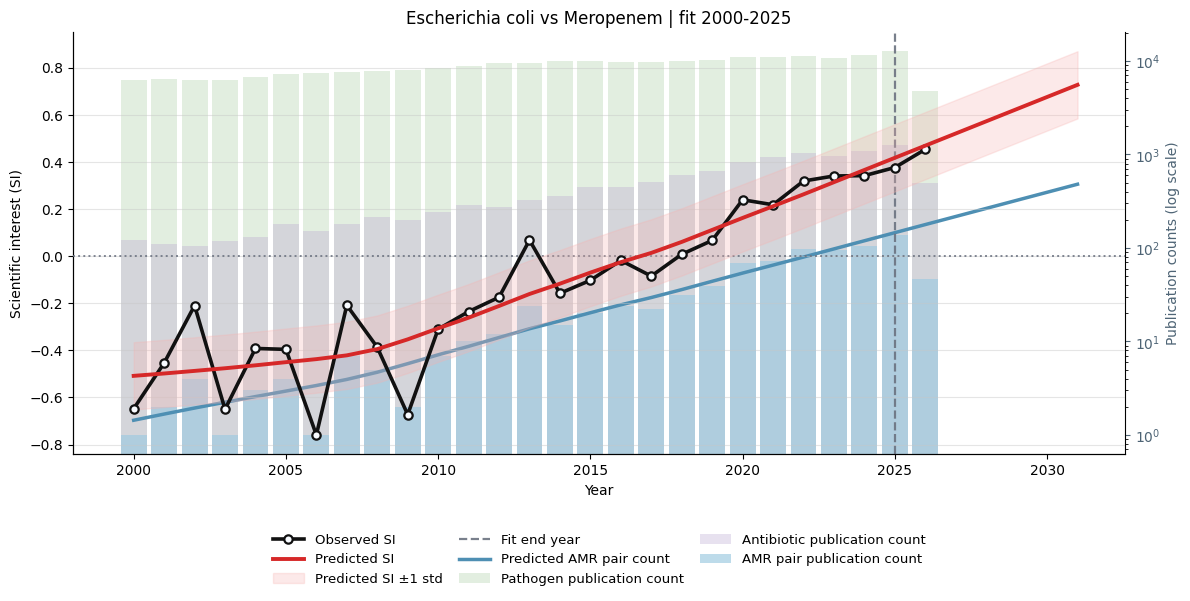

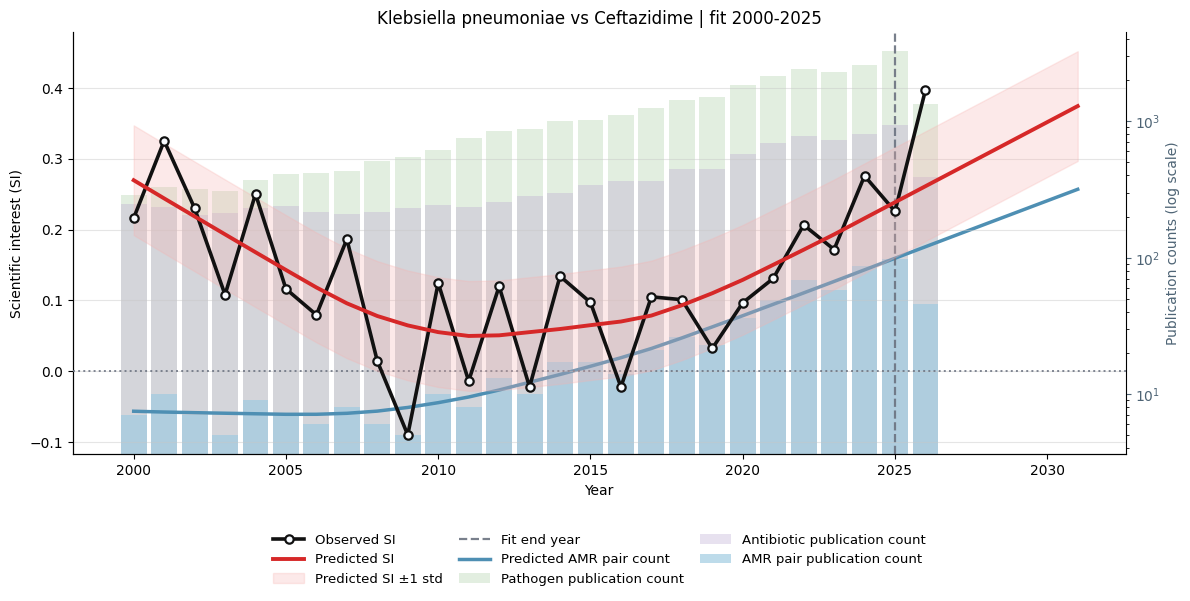

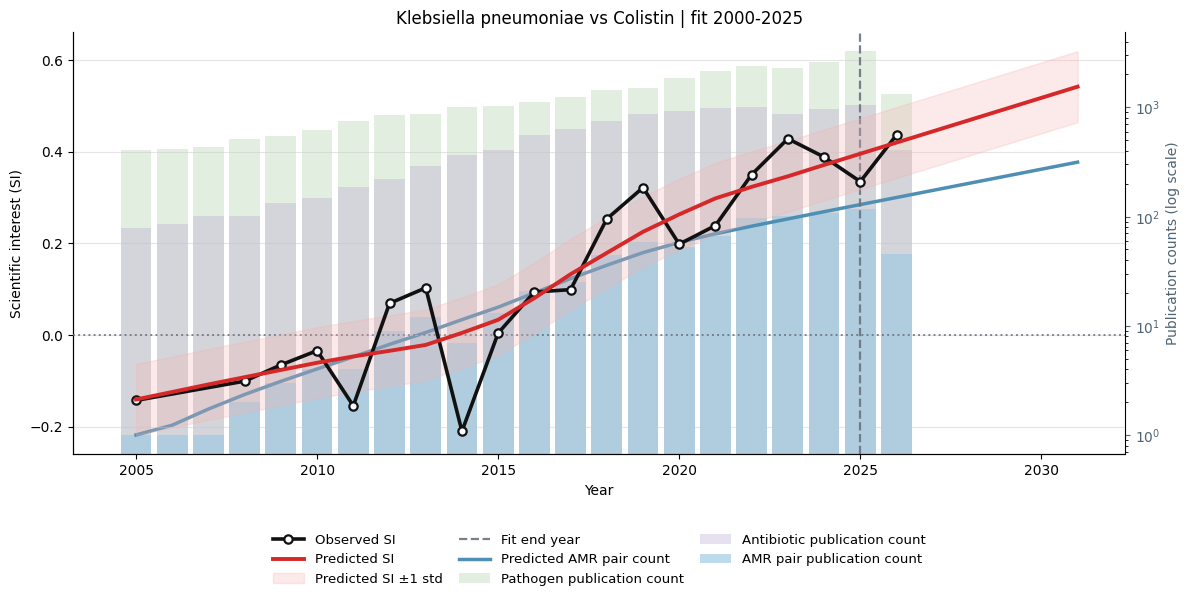

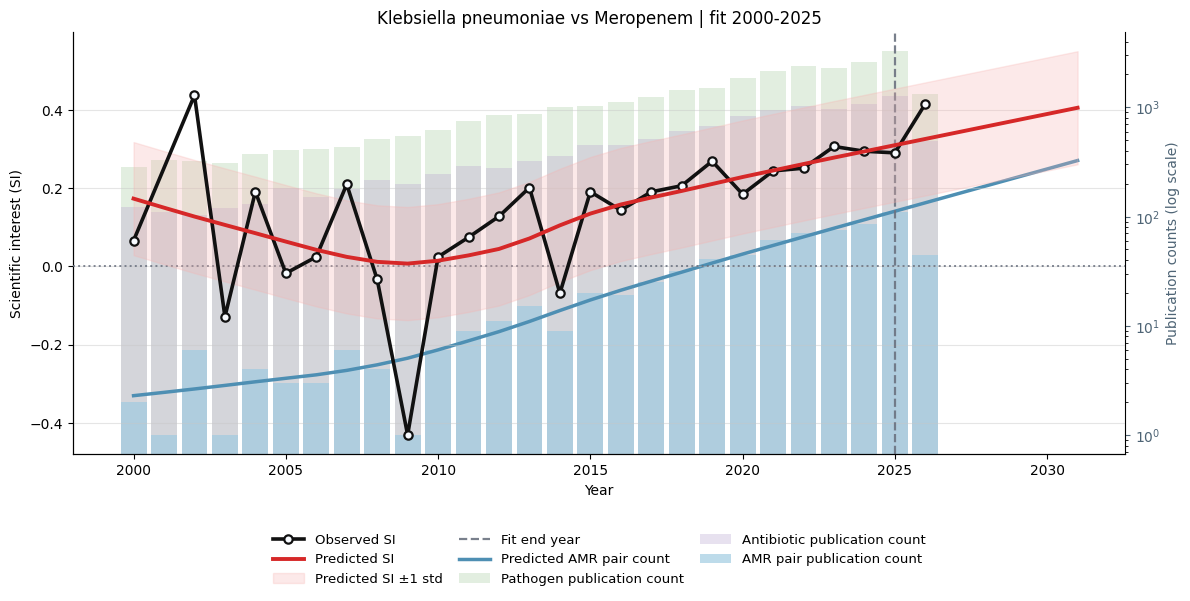

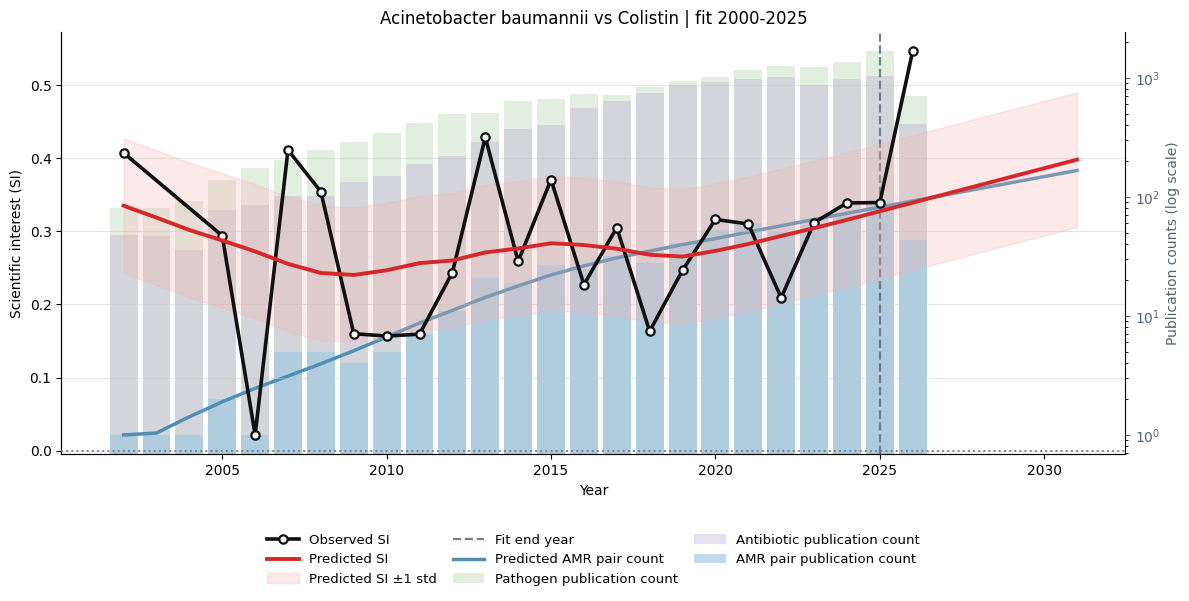

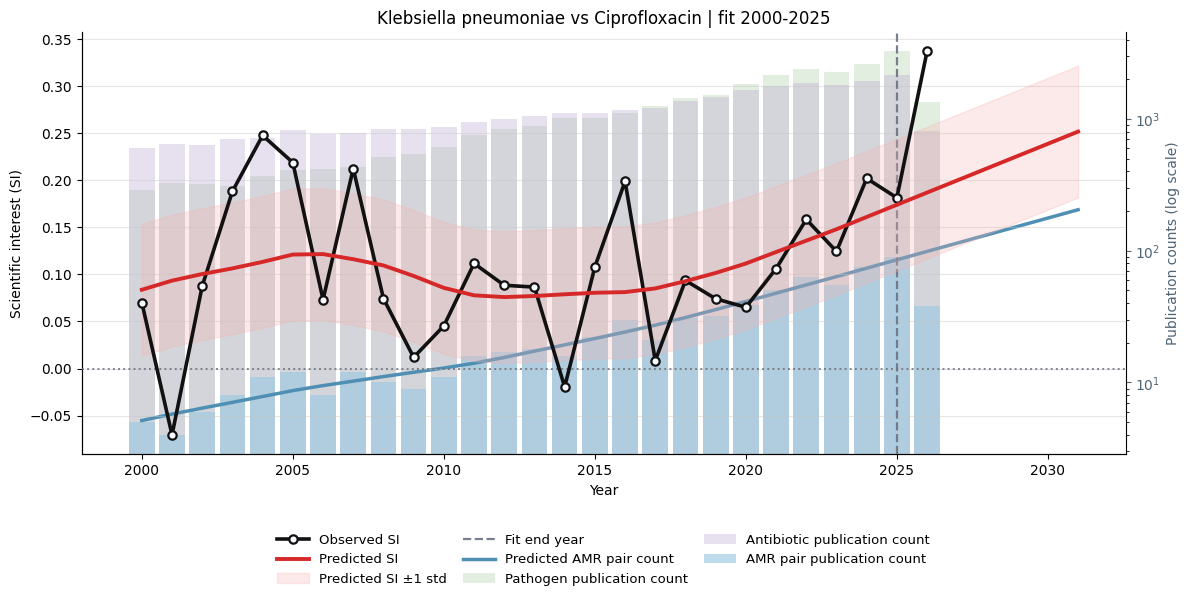

Saved 52 plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/glass_yearly_si_plots
Displayed 10 plots inline.
Saved GLASS SI plots: 52 -> /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/glass_yearly_si_plots


In [8]:
saved_si_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=glass_plot_pairs_df,
    output_dir=GLASS_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=len(glass_plot_pairs_df),
    loess_frac=LOESS_FRAC,
    loess_degree=LOESS_DEGREE,
    tail_damping_years=TAIL_DAMPING_YEARS,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)

print(f"Saved GLASS SI plots: {saved_si_plots:,} -> {GLASS_SI_PLOT_DIR}")